In [5]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re
import time

In [6]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/151.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/avif,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.9",
    "Connection": "keep-alive"
}

In [7]:
brands = [
    "maruti",
    "hyundai",
    "tata",
    "honda",
    "mahindra",
    "kia",
    "toyota",
    "renault",
    "ford",
    "volkswagen",
    "skoda",
    "mg",
    "nissan",
    "jeep",
    "audi",
    "bmw",
    "mercedes-benz"
]

all_cars = []
unique_cars = set()

session = requests.Session()
session.headers.update(headers)

for brand in brands:

    print("Scraping:", brand)

    # Start with only 2 pages for testing
    for page in range(1, 3):

        url = f"https://www.cars24.com/buy-used-{brand}-cars/?page={page}"

        try:
            response = session.get(url, timeout=20)

            print("Page:", page, "Status:", response.status_code)

            if response.status_code != 200:
                print("Skipping page:", page)
                continue

            soup = BeautifulSoup(response.text, "html.parser")

            text = soup.get_text(" ")

            cars = text.split("Cars24 Owned Stock")

            for item in cars:

                try:

                    # Year
                    year_match = re.search(r'20\d{2}', item)

                    if not year_match:
                        continue

                    year = year_match.group()

                    # Name
                    name_match = re.search(
                        r'20\d{2}\s.*?(?=\d{1,3}\,\d{3}\skm)',
                        item
                    )

                    if not name_match:
                        continue

                    name = name_match.group()

                    # KM
                    kms_match = re.search(
                        r'\d{1,3}\,\d{3}\skm',
                        item
                    )

                    if not kms_match:
                        continue

                    kms = kms_match.group()

                    # Fuel
                    fuel_match = re.search(
                        r'(Petrol|Diesel|CNG|Electric)',
                        item
                    )

                    if not fuel_match:
                        continue

                    fuel = fuel_match.group()

                    # Transmission
                    transmission_match = re.search(
                        r'(Manual|Automatic|Auto)',
                        item
                    )

                    if not transmission_match:
                        continue

                    transmission = transmission_match.group()

                    # EMI
                    emi_match = re.search(
                        r'EMI\s₹[\d,]+/m',
                        item
                    )

                    if emi_match:
                        emi = emi_match.group()
                    else:
                        emi = "Not Available"

                    # Price
                    prices = re.findall(
                        r'₹[\d.]+',
                        item
                    )

                    if len(prices) > 0:
                        price = prices[-1]
                    else:
                        price = "0"

                    # Unique Check
                    car_tuple = (
                        name,
                        kms,
                        fuel,
                        transmission,
                        emi,
                        price
                    )

                    if car_tuple not in unique_cars:

                        unique_cars.add(car_tuple)

                        all_cars.append([
                            name,
                            kms,
                            fuel,
                            transmission,
                            emi,
                            price,
                            year
                        ])

                except Exception:
                    continue

            # Wait between requests
            time.sleep(5)

        except requests.exceptions.RequestException as e:

            print("Connection error:", e)
            print("Waiting before retry...")

            time.sleep(10)

            continue

print("Scraping completed!")
print("Total cars collected:", len(all_cars))

Scraping: maruti
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: hyundai
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: tata
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: honda
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: mahindra
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: kia
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: toyota
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: renault
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: ford
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: volkswagen
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: skoda
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: mg
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: nissan
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: jeep
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: audi
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: bmw
Page: 1 Status: 200
Page: 2 Status: 200
Scraping: mercedes-benz
Page: 1 Status: 200
Page: 2 Status: 200
Scraping completed!
Total cars colle

In [19]:
df = pd.DataFrame(all_cars, columns=[
    "Car_Name",
    "Kilometers",
    "Fuel_Type",
    "Transmission",
    "EMI",
    "Price",
    "Model_Year"
])

print(df.shape)
df.head()

(293, 7)


,Car_Name,Kilometers,Fuel_Type,Transmission,EMI,Price,Model_Year
0,2014 Maruti Swift VXI,"95,449 km",Petrol,Manual,"EMI ₹9,594/m",₹2.89,2014
1,"2016 Maruti Wagon R 1.0 VXI 1,","11,095 km",Petrol,Manual,"EMI ₹5,497/m",₹2.47,2016
2,2013 Maruti Ertiga VXI,"42,781 km",Petrol,Manual,"EMI ₹17,776/m",₹3.78,2013
3,"2018 Maruti Swift ZXI 1,","28,856 km",CNG,Manual,"EMI ₹8,485/m",₹3.81,2018
4,2018 Maruti Alto 800 VXI,"23,175 km",Petrol,Manual,"EMI ₹3,776/m",₹2.14,2018


In [20]:
# RECREATE PRICE_LAKH

df["Price_Lakh"] = (
    df["Price"]
    .astype(str)
    .str.replace("₹", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["Price_Lakh"] = pd.to_numeric(
    df["Price_Lakh"],
    errors="coerce"
)

print(df[["Price", "Price_Lakh"]].head())

   Price  Price_Lakh
0  ₹2.89        2.89
1  ₹2.47        2.47
2  ₹3.78        3.78
3  ₹3.81        3.81
4  ₹2.14        2.14


In [21]:
# RECREATE EMI_AMOUNT

df["EMI_Amount"] = (
    df["EMI"]
    .astype(str)
    .str.replace("EMI ₹", "", regex=False)
    .str.replace("/m", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
)

df["EMI_Amount"] = pd.to_numeric(
    df["EMI_Amount"],
    errors="coerce"
)

print(df[["EMI", "EMI_Amount"]].head())

             EMI  EMI_Amount
0   EMI ₹9,594/m      9594.0
1   EMI ₹5,497/m      5497.0
2  EMI ₹17,776/m     17776.0
3   EMI ₹8,485/m      8485.0
4   EMI ₹3,776/m      3776.0


In [22]:
# RECREATE BRAND

brands = [
    "Maruti",
    "Hyundai",
    "Tata",
    "Honda",
    "Mahindra",
    "Kia",
    "Toyota",
    "Renault",
    "Ford",
    "Volkswagen",
    "Skoda",
    "MG",
    "Nissan",
    "Jeep",
    "Audi",
    "BMW",
    "Mercedes-Benz"
]

pattern = r"\b(" + "|".join(brands) + r")\b"

df["Brand"] = (
    df["Car_Name"]
    .str.extract(
        pattern,
        flags=re.IGNORECASE,
        expand=False
    )
    .str.title()
)

# Fix Mercedes-Benz
df.loc[
    df["Car_Name"].str.contains(
        "Mercedes Benz",
        case=False,
        na=False
    ),
    "Brand"
] = "Mercedes-Benz"

print("Brand extraction completed.")

print(
    df["Brand"].value_counts(
        dropna=False
    )
)

Brand extraction completed.
Brand
Maruti           20
Hyundai          20
Jeep             20
Nissan           20
Mg               20
Skoda            20
Volkswagen       20
Ford             20
Renault          20
Toyota           20
Kia              20
Mahindra         20
Honda            20
Tata             20
Mercedes-Benz     6
Audi              4
Bmw               3
Name: count, dtype: int64


In [23]:
# 8. CONVERT MODEL YEAR

df["Model_Year"] = pd.to_numeric(
    df["Model_Year"],
    errors="coerce"
)

print("Model Year Data Type:")
print(df["Model_Year"].dtype)

print("\nMissing Model Year Values:")
print(df["Model_Year"].isnull().sum())

Model Year Data Type:
int64

Missing Model Year Values:
0


In [24]:
# 9. DATA QUALITY REPORT

quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isnull().sum().values,
    "Missing %": (
        df.isnull().sum().values / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique().values
})

display(quality_report)

,Column,Data Type,Missing Values,Missing %,Unique Values
0,Car_Name,object,0,0.00,267
1,Kilometers,object,0,0.00,293
2,Fuel_Type,object,0,0.00,3
3,Transmission,object,0,0.00,2
4,EMI,object,0,0.00,288
5,Price,object,0,0.00,257
6,Model_Year,int64,0,0.00,14
7,Price_Lakh,float64,0,0.00,257
8,EMI_Amount,float64,1,0.34,287
9,Brand,object,0,0.00,17


In [25]:
# 10. CHECK DUPLICATE RECORDS

print(
    "Total Duplicate Rows:",
    df.duplicated().sum()
)

Total Duplicate Rows: 0


In [26]:
# 11. FUEL TYPE DISTRIBUTION

print("Fuel Type Distribution:")

print(
    df["Fuel_Type"].value_counts()
)

Fuel Type Distribution:
Fuel_Type
Petrol    219
Diesel     60
CNG        14
Name: count, dtype: int64


In [27]:
# 12. TRANSMISSION DISTRIBUTION

print("Transmission Distribution:")

print(
    df["Transmission"].value_counts()
)

Transmission Distribution:
Transmission
Manual    237
Auto       56
Name: count, dtype: int64


In [28]:
# 13. MODEL YEAR DISTRIBUTION
print("Model Year Distribution:")
print(
    df["Model_Year"]
    .value_counts()
    .sort_index()
)

Model Year Distribution:
Model_Year
2013     6
2014    10
2015    13
2016    25
2017    25
2018    41
2019    30
2020    36
2021    39
2022    38
2023    12
2024    11
2025     6
2026     1
Name: count, dtype: int64


In [29]:
# 14. PRICE STATISTICS

print("Price Statistics:")

print(
    df["Price_Lakh"].describe()
)

Price Statistics:
count    293.000000
mean       6.946109
std        5.166764
min        1.580000
25%        3.850000
50%        5.680000
75%        8.130000
max       41.130000
Name: Price_Lakh, dtype: float64


In [30]:
# 15. KILOMETERS STATISTICS

print("Kilometers Statistics:")

print(
    df["Kilometers"].describe()
)

Kilometers Statistics:
count           293
unique          293
top       95,449 km
freq              1
Name: Kilometers, dtype: object


In [31]:
# 16. EMI STATISTICS

print("EMI Statistics:")

print(
    df["EMI_Amount"].describe()
)

EMI Statistics:
count      292.000000
mean     13920.109589
std      10229.164695
min       3085.000000
25%       8054.250000
50%      11446.500000
75%      15367.500000
max      70425.000000
Name: EMI_Amount, dtype: float64


In [32]:
# 17. CHECK PRICE OUTLIERS

Q1 = df["Price_Lakh"].quantile(0.25)
Q3 = df["Price_Lakh"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

outliers = df[
    (df["Price_Lakh"] < lower_limit) |
    (df["Price_Lakh"] > upper_limit)
]

print(
    "\nNumber of Price Outliers:",
    len(outliers)
)

display(
    outliers[
        [
            "Car_Name",
            "Brand",
            "Price_Lakh",
            "Model_Year"
        ]
    ]
)

Q1: 3.85
Q3: 8.13
IQR: 4.280000000000001
Lower Limit: -2.5700000000000016
Upper Limit: 14.550000000000002

Number of Price Outliers: 18


,Car_Name,Brand,Price_Lakh,Model_Year
116,2023 KIA SELTOS GTX PLUS 1.5 DIESEL AT,Kia,15.20,2023
123,2026 Toyota URBAN CRUISER HYRYDER G (O) 2WD ...,Toyota,15.39,2026
126,2024 Toyota Innova Crysta GX Plus 8 STR,Toyota,22.85,2024
128,2018 Toyota Innova Crysta 2.4 VX 7 STR,Toyota,14.92,2018
129,2017 Toyota Fortuner 2.8 4X2 MT,Toyota,20.63,2017
134,2024 Toyota Fortuner 4X2 MT 2.8 DIESEL,Toyota,31.32,2024
279,2023 Jeep Compass LIMITED (O) 2.0 DIESEL 4X4...,Jeep,18.76,2023
280,2019 Audi Q5 40 TDI PREMIUM PLUS,Audi,26.73,2019
282,2022 Audi A4 40 TFSI PREMIUM PLUS,Audi,26.23,2022
283,2024 Audi A4 40 TFSI PREMIUM PLUS,Audi,18.30,2024


In [33]:
# 18. FINAL DATA QUALITY CHECK

print("========== FINAL DATA QUALITY CHECK ==========")

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

========== FINAL DATA QUALITY CHECK ==========

Dataset Shape:
(293, 10)

Missing Values:
Car_Name        0
Kilometers      0
Fuel_Type       0
Transmission    0
EMI             0
Price           0
Model_Year      0
Price_Lakh      0
EMI_Amount      1
Brand           0
dtype: int64

Duplicate Rows:
0

Data Types:
Car_Name         object
Kilometers       object
Fuel_Type        object
Transmission     object
EMI              object
Price            object
Model_Year        int64
Price_Lakh      float64
EMI_Amount      float64
Brand            object
dtype: object


In [34]:
# 19. FINAL CLEAN DATASET

display(
    df[
        [
            "Car_Name",
            "Brand",
            "Kilometers",
            "Fuel_Type",
            "Transmission",
            "EMI_Amount",
            "Price_Lakh",
            "Model_Year"
        ]
    ].head(10)
)

,Car_Name,Brand,Kilometers,Fuel_Type,Transmission,EMI_Amount,Price_Lakh,Model_Year
0,2014 Maruti Swift VXI,Maruti,"95,449 km",Petrol,Manual,9594.0,2.89,2014
1,"2016 Maruti Wagon R 1.0 VXI 1,",Maruti,"11,095 km",Petrol,Manual,5497.0,2.47,2016
2,2013 Maruti Ertiga VXI,Maruti,"42,781 km",Petrol,Manual,17776.0,3.78,2013
3,"2018 Maruti Swift ZXI 1,",Maruti,"28,856 km",CNG,Manual,8485.0,3.81,2018
4,2018 Maruti Alto 800 VXI,Maruti,"23,175 km",Petrol,Manual,3776.0,2.14,2018
5,2021 Maruti Swift VXI,Maruti,"60,180 km",Petrol,Manual,10370.0,5.87,2021
6,2024 Maruti Swift VXI,Maruti,"23,779 km",Petrol,Manual,10945.0,6.20,2024
7,2025 Maruti Swift ZXi Plus Dual Tone,Maruti,"10,434 km",Petrol,Manual,13787.0,7.81,2025
8,2016 Maruti Ertiga VXI,Maruti,"44,162 km",CNG,Manual,16893.0,5.09,2016
9,"2016 Maruti Swift VXI 1,",Maruti,"01,888 km",Petrol,Manual,11239.0,5.05,2016


In [35]:
# 20. SAVE CLEAN DATASET

df.to_csv(
    "cars24_clean.csv",
    index=False
)

print(
    "Clean Dataset Shape:",
    df.shape
)

print(
    "\nClean dataset saved successfully."
)

Clean Dataset Shape: (293, 10)

Clean dataset saved successfully.


In [36]:
# 21. BRAND-WISE AVERAGE PRICE

brand_price = (
    df.groupby("Brand")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Price by Brand:")

display(
    brand_price.reset_index()
)

Average Price by Brand:


,Brand,Price_Lakh
0,Mercedes-Benz,26.776667
1,Audi,21.415000
2,Bmw,18.133333
3,Toyota,10.500500
4,Mg,9.612500
5,Kia,8.697500
6,Skoda,7.893000
7,Jeep,7.890000
8,Mahindra,6.984500
9,Volkswagen,5.188000


In [37]:
# 22. BRAND-WISE CAR COUNT

brand_count = (
    df["Brand"]
    .value_counts()
)

print("Number of Cars by Brand:")

display(
    brand_count.reset_index(
        name="Car_Count"
    )
)

Number of Cars by Brand:


,Brand,Car_Count
0,Maruti,20
1,Hyundai,20
2,Jeep,20
3,Nissan,20
4,Mg,20
5,Skoda,20
6,Volkswagen,20
7,Ford,20
8,Renault,20
9,Toyota,20


In [38]:
# 23. FUEL TYPE VS AVERAGE PRICE

fuel_price = (
    df.groupby("Fuel_Type")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Price by Fuel Type:")

display(
    fuel_price.reset_index()
)

Average Price by Fuel Type:


,Fuel_Type,Price_Lakh
0,Diesel,9.700667
1,Petrol,6.290776
2,CNG,5.392143


In [39]:
# 24. TRANSMISSION VS AVERAGE PRICE

transmission_price = (
    df.groupby("Transmission")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Price by Transmission:")

display(
    transmission_price.reset_index()
)

Average Price by Transmission:


,Transmission,Price_Lakh
0,Auto,12.257321
1,Manual,5.691139


In [40]:
# 25. MODEL YEAR VS AVERAGE PRICE

year_price = (
    df.groupby("Model_Year")["Price_Lakh"]
    .mean()
    .sort_index()
)

print("Average Price by Model Year:")

display(
    year_price.reset_index()
)

Average Price by Model Year:


,Model_Year,Price_Lakh
0,2013,3.176667
1,2014,3.864000
2,2015,3.653077
3,2016,4.338400
4,2017,4.655600
5,2018,6.587561
6,2019,6.380000
7,2020,7.302778
8,2021,7.083846
9,2022,9.593158


In [41]:
# 26. KILOMETERS VS AVERAGE PRICE

km_price = (
    df.groupby("Kilometers")["Price_Lakh"]
    .mean()
    .sort_index()
)

print("Kilometers vs Price:")

display(
    km_price.reset_index().head(20)
)

Kilometers vs Price:


,Kilometers,Price_Lakh
0,"01,888 km",5.05
1,"02,150 km",5.04
2,"02,165 km",4.62
3,"02,238 km",1.81
4,"03,764 km",7.57
5,"03,873 km",4.04
6,"07,349 km",5.22
7,"07,784 km",5.12
8,"09,199 km",5.25
9,"09,998 km",8.23


In [43]:
# 26. CLEAN KILOMETERS AND CREATE KM RANGE

df["Kilometers"] = (
    df["Kilometers"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("km", "", regex=False)
    .str.strip()
)

df["Kilometers"] = pd.to_numeric(
    df["Kilometers"],
    errors="coerce"
)

print("Kilometers Data Type:")
print(df["Kilometers"].dtype)

print("\nMissing Kilometer Values:")
print(df["Kilometers"].isnull().sum())

Kilometers Data Type:
int64

Missing Kilometer Values:
0


In [45]:
# 27. KILOMETER RANGE VS AVERAGE PRICE

df["KM_Range"] = pd.cut(
    df["Kilometers"],
    bins=[0, 20000, 40000, 60000, 80000, 100000],
    labels=[
        "0-20K km",
        "20K-40K km",
        "40K-60K km",
        "60K-80K km",
        "80K-100K km"
    ]
)

km_range_price = (
    df.groupby(
        "KM_Range",
        observed=True
    )["Price_Lakh"]
    .mean()
    .reset_index()
)

print("Average Price by Kilometer Range:")

display(km_range_price)

Average Price by Kilometer Range:


,KM_Range,Price_Lakh
0,0-20K km,8.311290
1,20K-40K km,9.059184
2,40K-60K km,6.576310
3,60K-80K km,6.417738
4,80K-100K km,5.381333


In [46]:
# 28. TOP 10 MOST EXPENSIVE CARS

top_10_expensive = (
    df[
        [
            "Car_Name",
            "Brand",
            "Price_Lakh",
            "Model_Year",
            "Kilometers",
            "Fuel_Type",
            "Transmission"
        ]
    ]
    .sort_values(
        by="Price_Lakh",
        ascending=False
    )
    .head(10)
)

print("Top 10 Most Expensive Cars:")

display(top_10_expensive)

Top 10 Most Expensive Cars:


,Car_Name,Brand,Price_Lakh,Model_Year,Kilometers,Fuel_Type,Transmission
290,2022 Mercedes Benz GLC CLASS 200 Progressive,Mercedes-Benz,41.13,2022,17116,Petrol,Auto
134,2024 Toyota Fortuner 4X2 MT 2.8 DIESEL,Toyota,31.32,2024,60847,Diesel,Manual
288,2022 Mercedes Benz A CLASS LIMOUSINE A 200d,Mercedes-Benz,27.63,2022,39616,Diesel,Auto
285,2020 BMW 2 SERIES GRAN COUPE 220D SPORTLINE,Bmw,26.97,2020,46765,Diesel,Auto
280,2019 Audi Q5 40 TDI PREMIUM PLUS,Audi,26.73,2019,77627,Diesel,Auto
282,2022 Audi A4 40 TFSI PREMIUM PLUS,Audi,26.23,2022,43059,Petrol,Auto
289,2018 Mercedes Benz E Class E 200 AVANTGARDE,Mercedes-Benz,26.13,2018,32856,Petrol,Auto
291,2018 Mercedes Benz C Class C 200 AVANTGARDE,Mercedes-Benz,23.97,2018,28269,Petrol,Auto
126,2024 Toyota Innova Crysta GX Plus 8 STR,Toyota,22.85,2024,69437,Diesel,Manual
292,2024 Mercedes Benz GLA Class 200,Mercedes-Benz,21.71,2024,22654,Petrol,Auto


In [47]:
# 29. TOP 10 CHEAPEST CARS

top_10_cheapest = (
    df[
        [
            "Car_Name",
            "Brand",
            "Price_Lakh",
            "Model_Year",
            "Kilometers",
            "Fuel_Type",
            "Transmission"
        ]
    ]
    .sort_values(
        by="Price_Lakh",
        ascending=True
    )
    .head(10)
)

print("Top 10 Cheapest Cars:")

display(top_10_cheapest)

Top 10 Cheapest Cars:


,Car_Name,Brand,Price_Lakh,Model_Year,Kilometers,Fuel_Type,Transmission
147,2017 Renault Kwid RXT 0.8,Renault,1.58,2017,45001,Petrol,Manual
154,2017 Renault Kwid RXT 1.0,Renault,1.72,2017,61347,Petrol,Manual
157,"2017 Renault Kwid RXL 1,",Renault,1.81,2017,2238,Petrol,Manual
152,2017 Renault Kwid RXL,Renault,1.86,2017,86988,Petrol,Manual
38,2015 Hyundai Grand i10 SPORTS EDITION 1.2L K...,Hyundai,1.88,2015,91133,Petrol,Manual
246,2018 Nissan Micra Active XV,Nissan,1.98,2018,63456,Petrol,Manual
23,2015 Hyundai Eon MAGNA +,Hyundai,2.05,2015,43518,Petrol,Manual
83,2016 Mahindra Kuv100 K4 6 STR,Mahindra,2.09,2016,95396,Petrol,Manual
4,2018 Maruti Alto 800 VXI,Maruti,2.14,2018,23175,Petrol,Manual
21,2014 Hyundai Santro Xing GLS,Hyundai,2.21,2014,73064,Petrol,Manual


In [48]:
# 29. TOP 10 CHEAPEST CARS

top_10_cheapest = (
    df[
        [
            "Car_Name",
            "Brand",
            "Price_Lakh",
            "Model_Year",
            "Kilometers",
            "Fuel_Type",
            "Transmission"
        ]
    ]
    .sort_values(
        by="Price_Lakh",
        ascending=True
    )
    .head(10)
)

print("Top 10 Cheapest Cars:")

display(top_10_cheapest)

Top 10 Cheapest Cars:


,Car_Name,Brand,Price_Lakh,Model_Year,Kilometers,Fuel_Type,Transmission
147,2017 Renault Kwid RXT 0.8,Renault,1.58,2017,45001,Petrol,Manual
154,2017 Renault Kwid RXT 1.0,Renault,1.72,2017,61347,Petrol,Manual
157,"2017 Renault Kwid RXL 1,",Renault,1.81,2017,2238,Petrol,Manual
152,2017 Renault Kwid RXL,Renault,1.86,2017,86988,Petrol,Manual
38,2015 Hyundai Grand i10 SPORTS EDITION 1.2L K...,Hyundai,1.88,2015,91133,Petrol,Manual
246,2018 Nissan Micra Active XV,Nissan,1.98,2018,63456,Petrol,Manual
23,2015 Hyundai Eon MAGNA +,Hyundai,2.05,2015,43518,Petrol,Manual
83,2016 Mahindra Kuv100 K4 6 STR,Mahindra,2.09,2016,95396,Petrol,Manual
4,2018 Maruti Alto 800 VXI,Maruti,2.14,2018,23175,Petrol,Manual
21,2014 Hyundai Santro Xing GLS,Hyundai,2.21,2014,73064,Petrol,Manual


In [49]:
# 30. FUEL TYPE VS TRANSMISSION

fuel_transmission = pd.crosstab(
    df["Fuel_Type"],
    df["Transmission"]
)

print("Fuel Type vs Transmission:")

display(fuel_transmission)

Fuel Type vs Transmission:


Transmission,Auto,Manual
Fuel_Type,,
CNG,3,11
Diesel,11,49
Petrol,42,177


In [50]:
# 31. BRAND VS FUEL TYPE

brand_fuel = pd.crosstab(
    df["Brand"],
    df["Fuel_Type"]
)

print("Brand vs Fuel Type:")

display(brand_fuel)

Brand vs Fuel Type:


Fuel_Type,CNG,Diesel,Petrol
Brand,,,
Audi,0,2,2
Bmw,0,1,2
Ford,0,8,12
Honda,2,0,18
Hyundai,2,2,16
Jeep,2,7,11
Kia,1,6,13
Mahindra,0,11,9
Maruti,2,1,17


In [51]:
# 32. BRAND VS TRANSMISSION

brand_transmission = pd.crosstab(
    df["Brand"],
    df["Transmission"]
)

print("Brand vs Transmission:")

display(brand_transmission)

Brand vs Transmission:


Transmission,Auto,Manual
Brand,,
Audi,4,0
Bmw,3,0
Ford,0,20
Honda,1,19
Hyundai,0,20
Jeep,8,12
Kia,5,15
Mahindra,1,19
Maruti,0,20


In [52]:
# 33. BRAND-WISE AVERAGE KILOMETERS

brand_km = (
    df.groupby("Brand")["Kilometers"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Kilometers by Brand:")

display(
    brand_km.reset_index()
)

Average Kilometers by Brand:


,Brand,Kilometers
0,Volkswagen,65181.300000
1,Jeep,63400.400000
2,Honda,60721.900000
3,Tata,59637.550000
4,Ford,59290.650000
5,Hyundai,57445.300000
6,Mahindra,55771.300000
7,Toyota,55564.000000
8,Audi,55215.000000
9,Renault,52754.850000


In [53]:
# 34. PRICE VS KILOMETERS CORRELATION

correlation = df[
    ["Price_Lakh", "Kilometers"]
].corr()

print("Price vs Kilometers Correlation:")

display(correlation)

Price vs Kilometers Correlation:


,Price_Lakh,Kilometers
Price_Lakh,1.000000,-0.188403
Kilometers,-0.188403,1.000000


In [54]:
# 35. PRICE DISTRIBUTION STATISTICS

price_summary = pd.DataFrame({
    "Metric": [
        "Minimum Price",
        "Average Price",
        "Median Price",
        "Maximum Price"
    ],
    "Value_Lakh": [
        df["Price_Lakh"].min(),
        df["Price_Lakh"].mean(),
        df["Price_Lakh"].median(),
        df["Price_Lakh"].max()
    ]
})

print("Price Summary:")

display(price_summary)

Price Summary:


,Metric,Value_Lakh
0,Minimum Price,1.580000
1,Average Price,6.946109
2,Median Price,5.680000
3,Maximum Price,41.130000


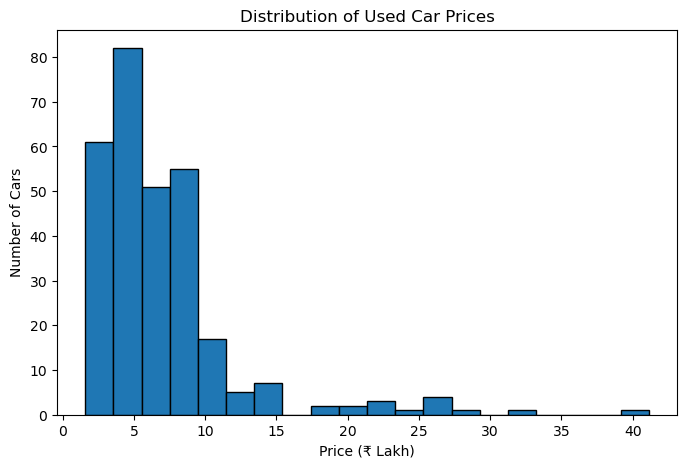

In [55]:
# 36. PRICE DISTRIBUTION

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df["Price_Lakh"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Used Car Prices")
plt.xlabel("Price (₹ Lakh)")
plt.ylabel("Number of Cars")

plt.show()

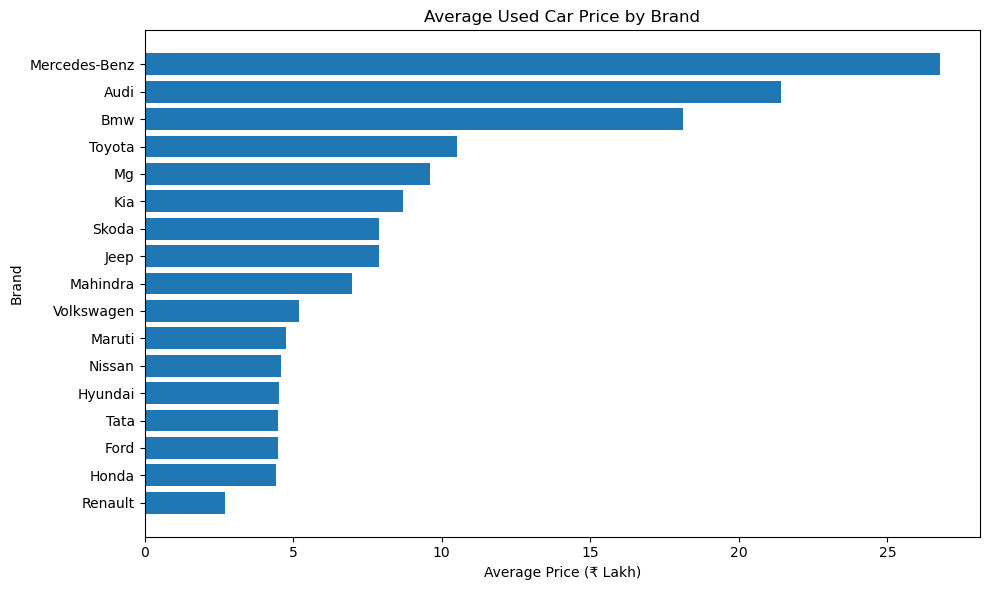

In [56]:
# 37. AVERAGE PRICE BY BRAND

plt.figure(figsize=(10, 6))

brand_price_plot = (
    df.groupby("Brand")["Price_Lakh"]
    .mean()
    .sort_values(ascending=True)
)

plt.barh(
    brand_price_plot.index,
    brand_price_plot.values
)

plt.title("Average Used Car Price by Brand")
plt.xlabel("Average Price (₹ Lakh)")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()

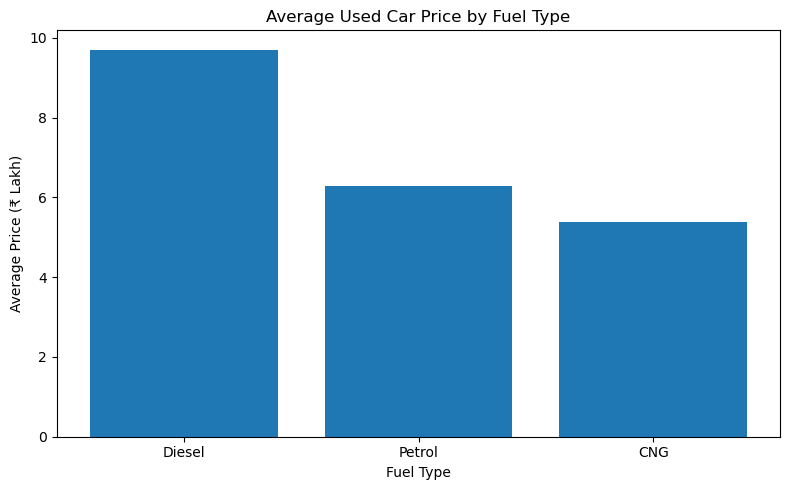

In [57]:
# 38. AVERAGE PRICE BY FUEL TYPE

plt.figure(figsize=(8, 5))

fuel_price_plot = (
    df.groupby("Fuel_Type")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
)

plt.bar(
    fuel_price_plot.index,
    fuel_price_plot.values
)

plt.title("Average Used Car Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Price (₹ Lakh)")

plt.tight_layout()
plt.show()

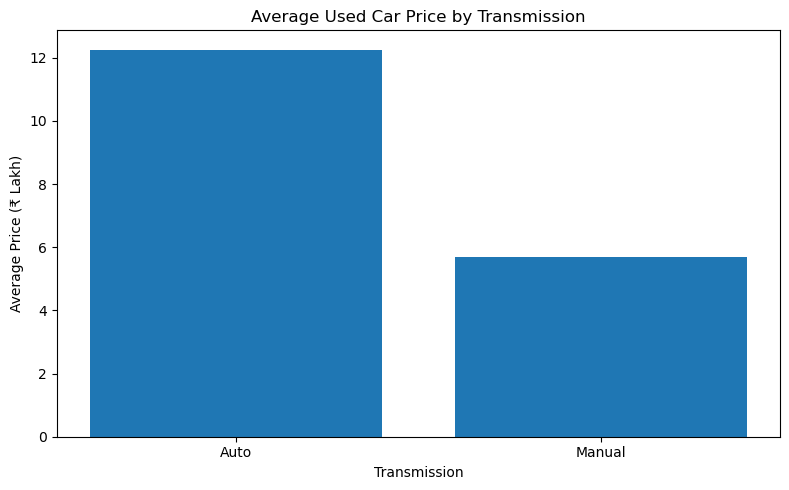

In [58]:
# 39. AVERAGE PRICE BY TRANSMISSION

plt.figure(figsize=(8, 5))

transmission_price_plot = (
    df.groupby("Transmission")["Price_Lakh"]
    .mean()
    .sort_values(ascending=False)
)

plt.bar(
    transmission_price_plot.index,
    transmission_price_plot.values
)

plt.title("Average Used Car Price by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Average Price (₹ Lakh)")

plt.tight_layout()
plt.show()

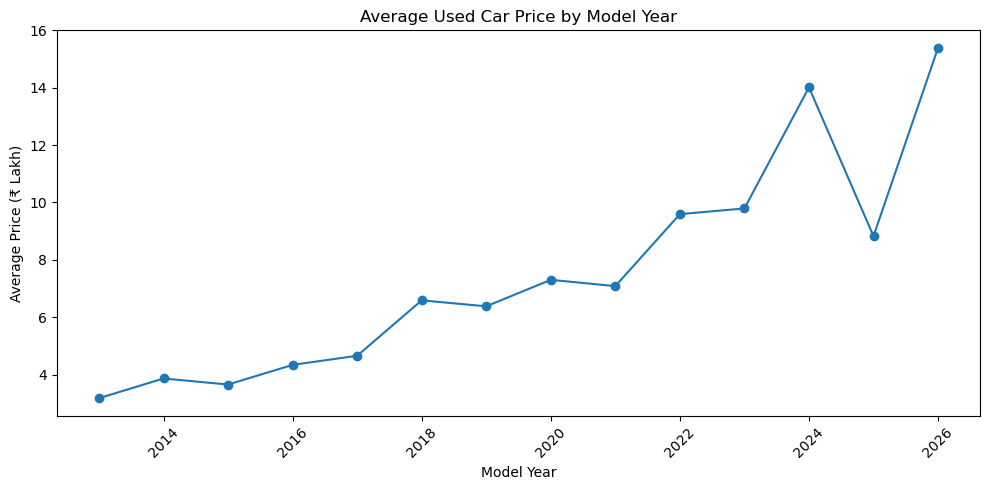

In [59]:
# 40. AVERAGE PRICE BY MODEL YEAR

plt.figure(figsize=(10, 5))

year_price_plot = (
    df.groupby("Model_Year")["Price_Lakh"]
    .mean()
    .sort_index()
)

plt.plot(
    year_price_plot.index,
    year_price_plot.values,
    marker="o"
)

plt.title("Average Used Car Price by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Average Price (₹ Lakh)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

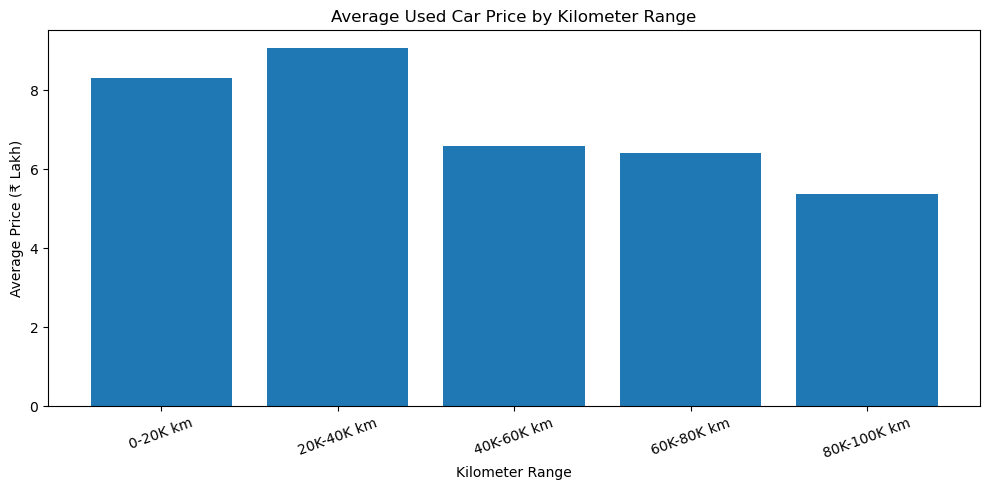

In [60]:
# 41. AVERAGE PRICE BY KILOMETER RANGE

plt.figure(figsize=(10, 5))

km_price_plot = (
    df.groupby("KM_Range", observed=True)["Price_Lakh"]
    .mean()
)

plt.bar(
    km_price_plot.index.astype(str),
    km_price_plot.values
)

plt.title("Average Used Car Price by Kilometer Range")
plt.xlabel("Kilometer Range")
plt.ylabel("Average Price (₹ Lakh)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

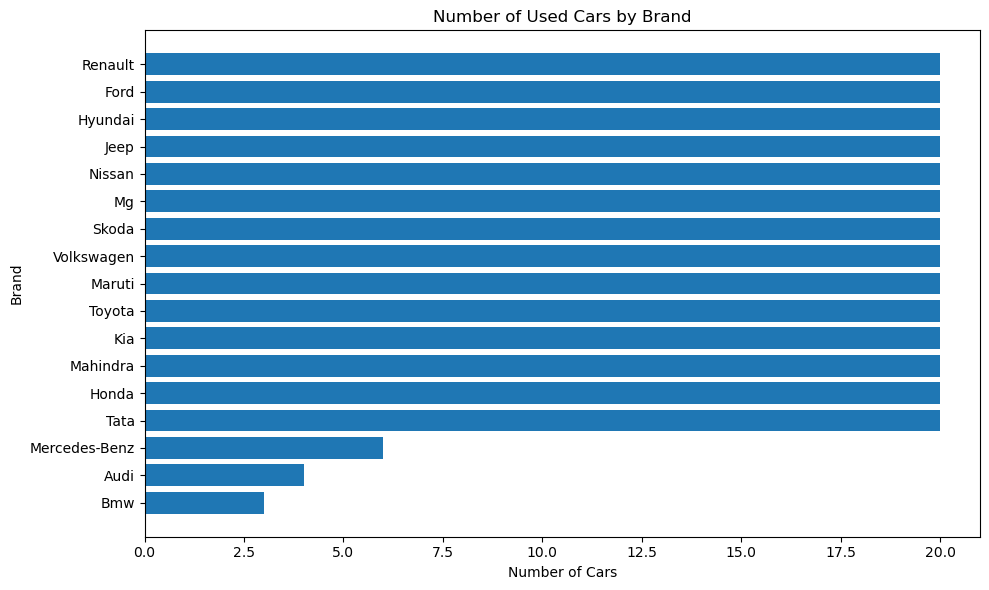

In [61]:
# 42. NUMBER OF CARS BY BRAND

plt.figure(figsize=(10, 6))

brand_count_plot = (
    df["Brand"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.barh(
    brand_count_plot.index,
    brand_count_plot.values
)

plt.title("Number of Used Cars by Brand")
plt.xlabel("Number of Cars")
plt.ylabel("Brand")

plt.tight_layout()
plt.show()


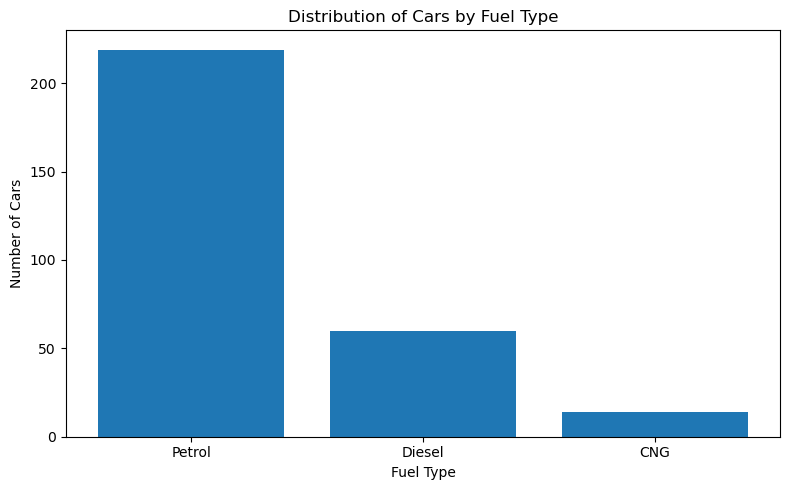

In [62]:
# 43. FUEL TYPE DISTRIBUTION

plt.figure(figsize=(8, 5))

fuel_count_plot = (
    df["Fuel_Type"]
    .value_counts()
)

plt.bar(
    fuel_count_plot.index,
    fuel_count_plot.values
)

plt.title("Distribution of Cars by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

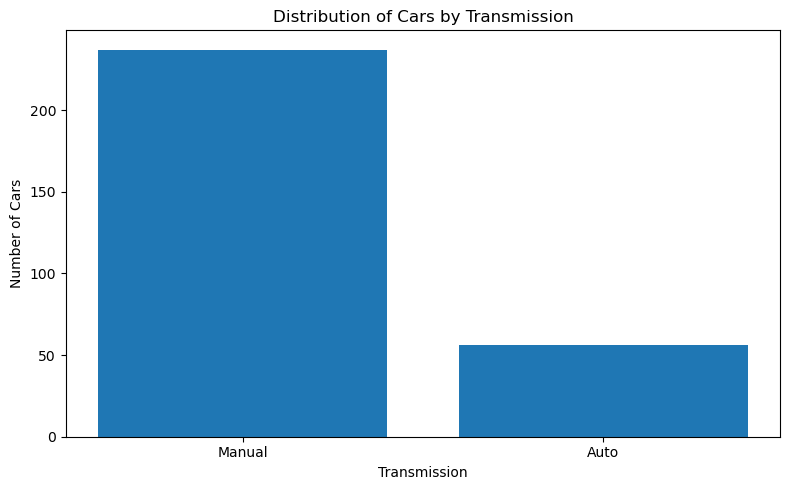

In [63]:
# 44. TRANSMISSION DISTRIBUTION

plt.figure(figsize=(8, 5))

transmission_count_plot = (
    df["Transmission"]
    .value_counts()
)

plt.bar(
    transmission_count_plot.index,
    transmission_count_plot.values
)

plt.title("Distribution of Cars by Transmission")
plt.xlabel("Transmission")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

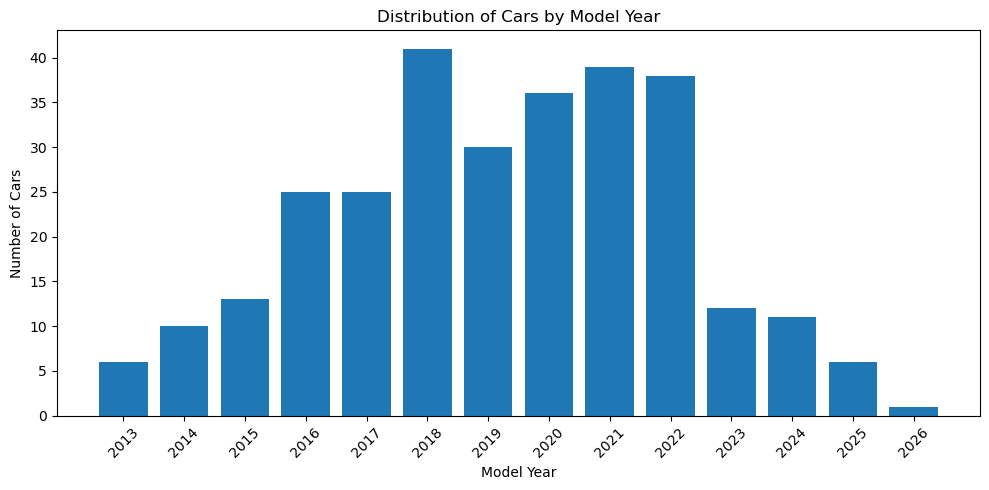

In [64]:
# 45. MODEL YEAR DISTRIBUTION

plt.figure(figsize=(10, 5))

year_count_plot = (
    df["Model_Year"]
    .value_counts()
    .sort_index()
)

plt.bar(
    year_count_plot.index.astype(str),
    year_count_plot.values
)

plt.title("Distribution of Cars by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Number of Cars")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

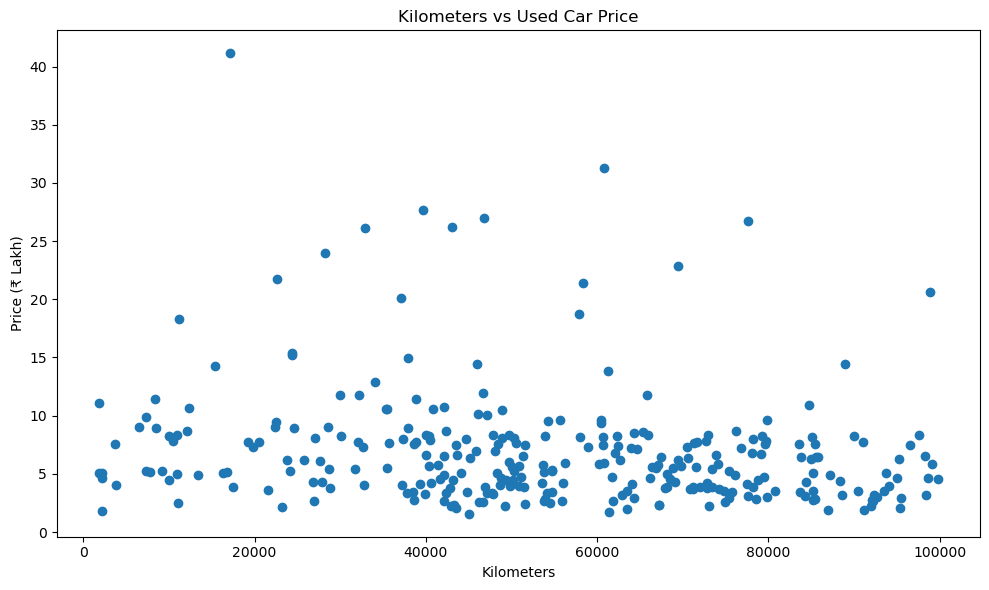

In [65]:
# 46. KILOMETERS VS PRICE

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Kilometers"],
    df["Price_Lakh"]
)

plt.title("Kilometers vs Used Car Price")
plt.xlabel("Kilometers")
plt.ylabel("Price (₹ Lakh)")

plt.tight_layout()
plt.show()